In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Importing the dataset

In [2]:
# city_pairs.csv ships with this repo.
# Source: Kaggle "International Airlines Traffic by City Pairs"
df = pd.read_csv("city_pairs.csv")

In [3]:
df.shape

(89320, 15)

In [4]:
df.head(10)

,Month,AustralianPort,ForeignPort,Country,Passengers_In,Freight_In_(tonnes),Mail_In_(tonnes),Passengers_Out,Freight_Out_(tonnes),Mail_Out_(tonnes),Passengers_Total,Freight_Total_(tonnes),Mail_Total_(tonnes),Year,Month_num
0,Jan-85,Adelaide,Auckland,New Zealand,1513,42.167,0.311,985,18.704,0.924,2498,60.871,1.235,1985,1
1,Jan-85,Adelaide,Bahrain,Bahrain,12,0.000,0.000,5,0.033,0.000,17,0.033,0.000,1985,1
2,Jan-85,Adelaide,Bombay,India,7,0.000,0.000,5,0.000,0.000,12,0.000,0.000,1985,1
3,Jan-85,Adelaide,Frankfurt,Germany,115,0.009,0.000,171,0.000,0.248,286,0.009,0.248,1985,1
4,Jan-85,Adelaide,London,UK,1567,2.800,0.000,1472,10.618,2.487,3039,13.418,2.487,1985,1
5,Jan-85,Adelaide,Muscat,Oman,17,0.000,0.000,14,0.100,0.000,31,0.100,0.000,1985,1
6,Jan-85,Adelaide,Rome,Italy,79,0.005,0.000,44,0.000,0.000,123,0.005,0.000,1985,1
7,Jan-85,Adelaide,Singapore,Singapore,2496,37.345,0.000,2037,133.203,0.112,4533,170.548,0.112,1985,1
8,Jan-85,Brisbane,Abu Dhabi,United Arab Emirates,0,0.000,0.000,3,0.000,0.000,3,0.000,0.000,1985,1
9,Jan-85,Brisbane,Auckland,New Zealand,7157,223.258,0.671,5652,33.032,3.218,12809,256.290,3.889,1985,1


In [5]:
df.loc[:,'Month']

0        Jan-85
1        Jan-85
2        Jan-85
3        Jan-85
4        Jan-85
          ...  
89315    Feb-25
89316    Feb-25
89317    Feb-25
89318    Feb-25
89319    Feb-25
Name: Month, Length: 89320, dtype: str

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 89320 entries, 0 to 89319
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Month                   89320 non-null  str    
 1   AustralianPort          89320 non-null  str    
 2   ForeignPort             89320 non-null  str    
 3   Country                 89320 non-null  str    
 4   Passengers_In           89320 non-null  int64  
 5   Freight_In_(tonnes)     89320 non-null  float64
 6   Mail_In_(tonnes)        89320 non-null  float64
 7   Passengers_Out          89320 non-null  int64  
 8   Freight_Out_(tonnes)    89320 non-null  float64
 9   Mail_Out_(tonnes)       89320 non-null  float64
 10  Passengers_Total        89320 non-null  int64  
 11  Freight_Total_(tonnes)  89320 non-null  float64
 12  Mail_Total_(tonnes)     89320 non-null  float64
 13  Year                    89320 non-null  int64  
 14  Month_num               89320 non-null  int64  
d

## Changing the month into a datetime format

In [7]:
# Assign with df['Month'] rather than df.loc[:, 'Month']. In pandas 3 the Month
# column has a real `str` dtype, and setitem through .loc refuses to put a
# datetime into it (TypeError). Plain assignment replaces the column instead.
df['Month'] = pd.to_datetime(df["Month"], format="%b-%y")
df['Month'].dtype

dtype('<M8[us]')

In [8]:
df.describe()

,Month,Passengers_In,Freight_In_(tonnes),Mail_In_(tonnes),Passengers_Out,Freight_Out_(tonnes),Mail_Out_(tonnes),Passengers_Total,Freight_Total_(tonnes),Mail_Total_(tonnes),Year,Month_num
count,89320,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000,89320.000000
mean,2003-07-15 03:06:53.040752,4561.972380,167.342670,7.442728,4491.480743,148.406850,4.628451,9053.453124,315.749520,12.071179,2003.077541,6.498959
min,1985-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1985.000000,1.000000
25%,1994-06-01 00:00:00,128.000000,0.002000,0.000000,133.000000,0.011750,0.000000,284.000000,0.781000,0.000000,1994.000000,3.000000
50%,2001-08-01 00:00:00,1290.000000,14.962000,0.000000,1265.000000,14.072000,0.000000,2573.000000,43.536000,0.105000,2001.000000,7.000000
75%,2013-02-01 00:00:00,4831.000000,136.583750,1.703000,4698.250000,118.125500,1.551250,9614.000000,275.003250,4.932000,2013.000000,10.000000
max,2025-02-01 00:00:00,90926.000000,6764.923000,393.705000,91078.000000,4996.582000,382.229000,170469.000000,9889.553000,566.993000,2025.000000,12.000000
std,NaN,8564.725065,407.415238,23.809746,8416.198365,363.853783,14.769693,16905.519449,728.108373,34.345207,11.222014,3.472430


## Any missing values ?

In [9]:
df.isnull().sum()

Month                     0
AustralianPort            0
ForeignPort               0
Country                   0
Passengers_In             0
Freight_In_(tonnes)       0
Mail_In_(tonnes)          0
Passengers_Out            0
Freight_Out_(tonnes)      0
Mail_Out_(tonnes)         0
Passengers_Total          0
Freight_Total_(tonnes)    0
Mail_Total_(tonnes)       0
Year                      0
Month_num                 0
dtype: int64

## Duplicated Values ?

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
print("Number of unique ports in australia for this dataset :", df.loc[:,'AustralianPort'].nunique())
print("They are:", df.loc[:,'AustralianPort'].unique())

Number of unique ports in australia for this dataset : 19
They are: <StringArray>
[              'Adelaide',               'Brisbane',                 'Cairns',
                 'Darwin',                 'Hobart',              'Melbourne',
         'Norfolk Island',                  'Perth',           'Port Hedland',
                 'Sydney',             'Townsville',       'Christmas Island',
                 'Broome', 'Gold Coast/Coolangatta',              'Newcastle',
               'Canberra',             'Gold Coast',         'Sunshine Coast',
     'Toowoomba Wellcamp']
Length: 19, dtype: str


## I want to find the amount of freight moving from each port by year

In [12]:
groupByYear = df.groupby(["AustralianPort","Year"])[["Freight_Out_(tonnes)","Passengers_Out"]].sum().reset_index()

In [13]:
groupByYear.head(10)

,AustralianPort,Year,Freight_Out_(tonnes),Passengers_Out
0,Adelaide,1985,2423.831,52681
1,Adelaide,1986,3476.573,66298
2,Adelaide,1987,4213.708,67927
3,Adelaide,1988,4494.134,68411
4,Adelaide,1989,4585.362,71553
5,Adelaide,1990,4756.714,88528
6,Adelaide,1991,6003.015,95124
7,Adelaide,1992,6297.629,100531
8,Adelaide,1993,7401.819,104129
9,Adelaide,1994,7352.383,102949


In [14]:
# Sort by total outward freight before taking the top 7. Order matters: .head(7)
# over an unsorted Series returns whatever comes first in the frame, not the
# largest, so the sort has to come first.
topPortsFreight = (
    groupByYear.groupby("AustralianPort")["Freight_Out_(tonnes)"]
    .sum()
    .sort_values(ascending=False)
    .head(7)
    .index
)
list(topPortsFreight)

['Sydney', 'Melbourne', 'Brisbane', 'Perth', 'Adelaide', 'Cairns', 'Darwin']

In [15]:
topPortsFreightData = groupByYear[groupByYear["AustralianPort"].isin(topPortsFreight)]

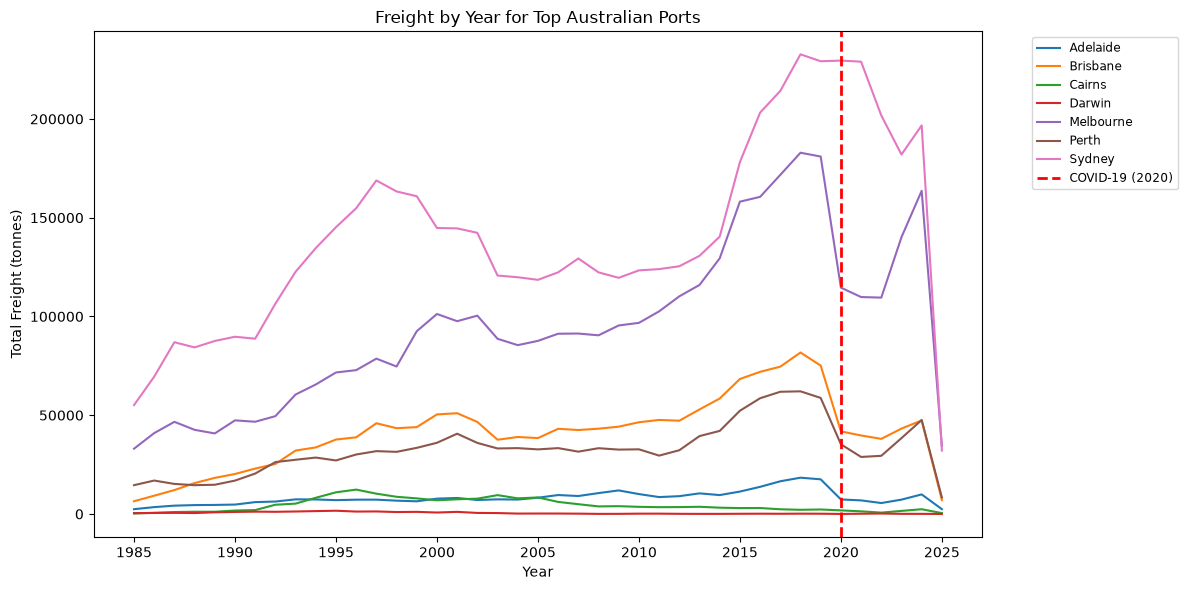

In [16]:
plt.figure(figsize=(12, 6))
for port in topPortsFreightData["AustralianPort"].unique():
    port_data = topPortsFreightData[topPortsFreightData["AustralianPort"]==port]
    plt.plot(port_data["Year"], port_data["Freight_Out_(tonnes)"], label=port)
plt.axvline(x=2020, color='red', linestyle='--', linewidth=2, label='COVID-19 (2020)')

plt.xlabel("Year")
plt.ylabel("Total Freight (tonnes)")
plt.title("Freight by Year for Top Australian Ports")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize="small")
plt.tight_layout()
plt.show()

In [17]:
topMailData = df.groupby("AustralianPort")["Mail_In_(tonnes)"].sum().sort_values()
topMailData.idxmax()

'Sydney'

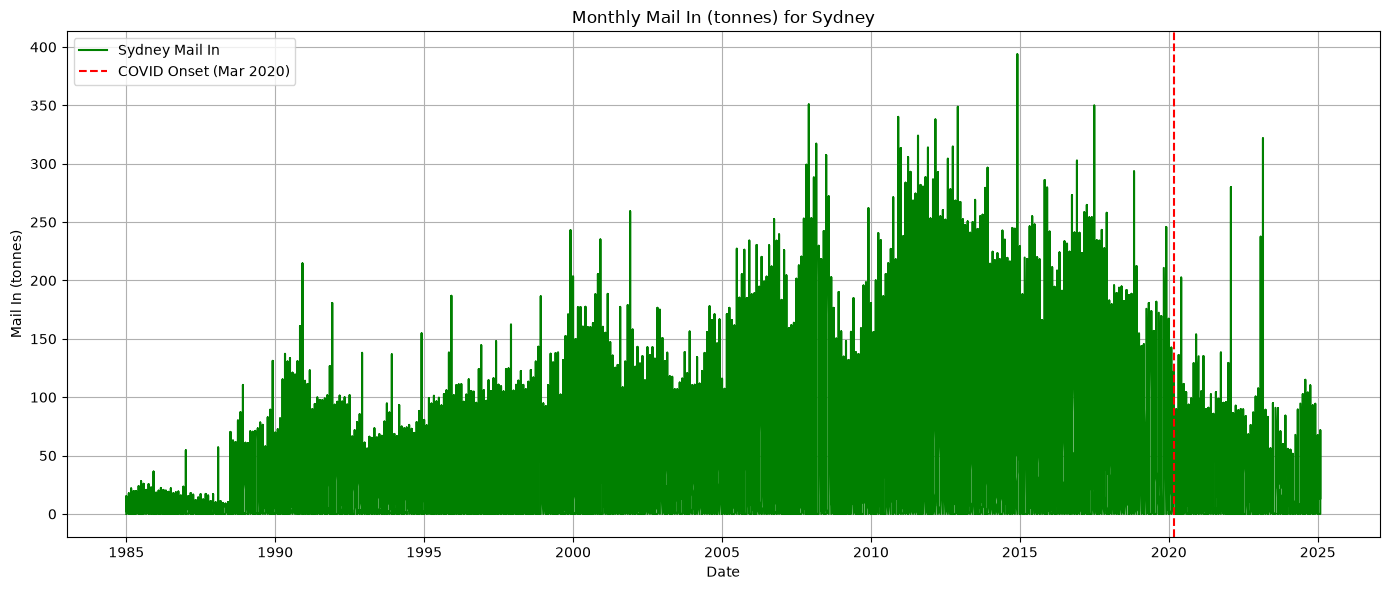

In [18]:
port_name = topMailData.idxmax()
port_data = df[df["AustralianPort"] == port_name].copy()

# Combine Year and Month_num into a datetime for plotting
port_data["Date"] = pd.to_datetime(port_data["Year"].astype(str) + "-" + port_data["Month_num"].astype(str), format="%Y-%m")

# Sort by date
port_data = port_data.sort_values("Date")

# Plotting
plt.figure(figsize=(14, 6))
plt.plot(port_data["Date"], port_data["Mail_In_(tonnes)"], label=f"{port_name} Mail In", color='green')

# Optional: Add a vertical line for COVID (March 2020)
plt.axvline(pd.to_datetime("2020-03"), color='red', linestyle='--', label="COVID Onset (Mar 2020)")

plt.title(f"Monthly Mail In (tonnes) for {port_name}")
plt.xlabel("Date")
plt.ylabel("Mail In (tonnes)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## What are the major trading partners for each port ?

In [19]:
partenerPorts = df.groupby(["AustralianPort","ForeignPort"])["Freight_Total_(tonnes)"].sum().reset_index()

In [20]:
top_partners = partenerPorts.loc[partenerPorts.groupby("AustralianPort")["Freight_Total_(tonnes)"].idxmax()].reset_index(drop=True)

In [21]:
top_partners

,AustralianPort,ForeignPort,Freight_Total_(tonnes)
0,Adelaide,Singapore,291404.729
1,Brisbane,Singapore,809647.500
2,Broome,Denpasar,0.132
3,Cairns,Hong Kong,74866.704
4,Canberra,Singapore,1278.715
5,Christmas Island,Jakarta,463.517
6,Darwin,Singapore,23351.391
7,Gold Coast,Kuala Lumpur,17050.695
8,Gold Coast/Coolangatta,Osaka,1147.139
9,Hobart,Hong Kong,770.346


In [22]:
top_partners["ForeignPort"].value_counts()

ForeignPort
Singapore       6
Auckland        5
Hong Kong       3
Denpasar        2
Jakarta         1
Kuala Lumpur    1
Osaka           1
Name: count, dtype: int64

In [23]:
# The headline result: which foreign port is the top trading partner,
# and for how many Australian ports.
print(f"Australian ports analysed : {top_partners['AustralianPort'].nunique()}")
print(f"Top partners             : {top_partners['ForeignPort'].nunique()} distinct foreign ports")
print(f"Singapore is the top partner for {top_partners['ForeignPort'].value_counts().get('Singapore', 0)} of "
      f"{top_partners['AustralianPort'].nunique()} ports")

Australian ports analysed : 19
Top partners             : 7 distinct foreign ports
Singapore is the top partner for 6 of 19 ports
